# Chiến lược thi

Trong phòng thi, thời gian là giới hạn chính. Còn 35 phút, đã có model ảnh khá tốt nhưng bài văn bản chưa có bài nộp nào: nên thử thêm cho bài ảnh hay làm bài văn bản? Bài này học cách chia thời gian giữa các bài, khi nào nên dừng cải tiến một bài, và cách luôn có một bài nộp hợp lệ trước khi thử cái mới.

Ví dụ trong bài là một buổi luyện **180 phút** gồm việc A về văn bản, B về ảnh và C về tìm kiếm có phản hồi. Với kỳ thi thật, các con số lấy theo thể lệ của kỳ thi đó.

> **Mục tiêu**
>
> - Ghi lại yêu cầu của mỗi bài: đầu vào, metric, tài nguyên, thời gian chạy, file nộp.
> - Quy điểm các bài về cùng thang để so sánh.
> - Lập kế hoạch thời gian cho cả buổi thi.
> - Đọc điểm public đúng mức tin cậy; luôn giữ một bài nộp hợp lệ.

## Đọc một bài để biết cần hoàn thành điều gì

Trong lập trình thi đấu, đọc đề thường kết thúc bằng một thuật toán và độ phức tạp. Với AI, ta còn phải xác định quy trình chấm. Bài có thể yêu cầu một file dự đoán, một model đã lưu hoặc một notebook chạy từ đầu. Nếu chỉ nộp dự đoán, thời gian tạo file nằm ở phía ta. Nếu bộ chấm chạy notebook, khởi động, đọc dữ liệu và model, huấn luyện và suy luận có thể cùng nằm trong giới hạn thời gian chạy (runtime). Hai dạng đó dẫn tới hai kế hoạch rất khác.

Ghi một bảng ngắn trước khi viết model. Mỗi ô cần trả lời một câu có thể kiểm: nhãn xuất hiện ở file nào; mẫu mới có cùng người, cùng camera hoặc cùng thời điểm với train không; metric cần nhãn hay xác suất; tên file và thứ tự ID phải là gì. “GPU có sẵn” chưa đủ: cần biết bộ nhớ, số tiến trình, model được cấp và việc tải thêm có được phép không.

| Điều cần hiểu | Ví dụ trong buổi luyện | Quyết định đi theo |
|---|---|---|
| Đơn vị một mẫu | Một đoạn văn; nhiều đoạn thuộc cùng tài liệu | Chia theo tài liệu nếu cần tổng quát sang tài liệu mới |
| Metric | Log loss, càng thấp càng tốt | Lưu xác suất, không chỉ lưu nhãn |
| Dạng nộp | CSV `id,probability` | Kiểm range, ID và thứ tự dòng |
| Runtime chấm | Giả định chỉ chạy inference | Đo đọc model và inference, không cộng nhầm thời gian luyện |
| Tài nguyên | CPU và dữ liệu có sẵn trên máy trong ví dụ | Chọn baseline không cần tải model |

Quy định thật luôn gắn với từng kỳ thi. **IOAI 2026, Individual Contest**: quy định chung nêu hai ngày, ba bài mỗi ngày, sáu giờ mỗi ngày. Phụ lục kỹ thuật đưa giới hạn đánh giá chung, nhưng đề từng bài có thể chỉ định giới hạn khác; repo công bố sau kỳ thi ghi runtime từng bài khác nhau. Vì vậy ta đọc đề cụ thể trước khi lập kế hoạch. [Rules & Technical Appendix 2026](https://ioai-official.org/wp-content/uploads/2026/06/IOAI2026-Contest-Rules-and-Tehnical-Appendix.pdf), [Individual Contest 2026](https://github.com/IOAI-official/IOAI-2026/tree/main/Individual-Contest).

Kỳ thi khác có yêu cầu khác. Ở **USA-NA-AIO 2026, Vòng 2**, mỗi bài mở yêu cầu nộp ba tệp: file dự đoán CSV, notebook chứa toàn bộ code và báo cáo mô tả model đã nộp cùng các hướng đã thử nhưng không dùng; có bài ghi rõ notebook không chạy được trên GPU L4 thì phần đó 0 điểm. Đề Vòng 1 còn ghi chất lượng lập luận là một tiêu chí chấm. Khi đó nhật ký thí nghiệm là nguyên liệu của bài làm, không chỉ là ghi chú riêng. [Đề Vòng 2, Ngày 1](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-1-problems.pdf#page=8), [đề Vòng 1](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=24).

**Hỏi nhanh.** Đề chấm bằng cách chạy lại notebook từ đầu trên máy chấm, giới hạn 5 phút. Đội chỉ bấm giờ dòng `model.predict(X_test)`, được 40 giây. Phép đo này còn thiếu gì?

- A. Thiếu thời gian đọc dữ liệu, nạp asset và train trước `predict`
- B. Chỉ thiếu bước ghi CSV, thường không đáng kể
- C. Không thiếu gì, vì `predict` là bước duy nhất tạo ra đáp án
- D. Chỉ cần nhân 40 giây với số seed dự định ensemble

<details><summary>Đáp án</summary>

A. Thiếu thời gian đọc dữ liệu, nạp asset và train trước `predict`

Runtime gắn với quy trình chấm, không gắn với tên một hàm. Máy chấm chạy mọi cell, kể cả đọc dữ liệu, nạp model và train lại. Một notebook train mất 6 phút sẽ hết giờ trước khi tới được `predict`. Ghi CSV có tốn thời gian, nhưng không phải phần thiếu chính. Nhân theo số seed chỉ ước lượng phần predict của một ensemble.

</details>



**Hỏi nhanh.** Metric là log loss trên 100 mẫu, và scorer cắt xác suất vào $[10^{-15}, 1 - 10^{-15}]$. Đội nộp nhãn cứng 0/1 thay cho xác suất, và đúng 90 mẫu. Log loss xấp xỉ bao nhiêu?

- A. 0.10, đúng bằng tỉ lệ đoán sai
- B. 0.105, bằng $-\ln 0.9$ vì model đúng 90%
- C. Không tính được, vì scorer báo lỗi với xác suất 0
- D. 3.45, tệ hơn cả nộp hằng 0.5 cho mọi mẫu, vốn được 0.693

<details><summary>Đáp án</summary>

D. 3.45, tệ hơn cả nộp hằng 0.5 cho mọi mẫu, vốn được 0.693

Mỗi mẫu sai bị tính $-\ln 10^{-15} \approx 34.5$, còn mẫu đúng gần 0. Trung bình là $10\cdot 34.5/100 \approx 3.45$. Nộp hằng 0.5 cho $\ln 2 \approx 0.693$, dù không học gì. 0.10 là tỉ lệ lỗi, tức thang của accuracy. $-\ln 0.9$ là log loss khi mọi mẫu được gán xác suất 0.9 cho lớp đúng, không phải khi nộp 0/1. Scorer ở đây đã cắt, nên không báo lỗi. Metric cần xác suất thì phải lưu xác suất ngay từ baseline.

</details>



## Có baseline trước khi có tham vọng

Baseline đầu tiên trả lời hai câu: ta có hiểu metric không, và đường từ dữ liệu tới bài nộp có chạy được không? Với văn bản, TF-IDF cùng logistic regression thường là mốc dễ dựng; với embedding có sẵn, linear probe hoặc kNN là mốc để kiểm shape và nhãn. Baseline của *ta* dùng để kiểm quy trình; baseline do ban tổ chức cung cấp còn có thể tham gia cách tính điểm. Đừng nhập hai ý đó làm một.

Quy tắc chuẩn hóa ở mục 2.5 của **IOAI 2026 Individual Contest** dùng điểm baseline làm mốc thấp. Ta minh họa công thức bằng dữ liệu tự đặt, với metric càng cao càng tốt:

$$N(s)=100\frac{s-b}{u-b}.$$

$s$ là metric của bài nộp, $b$ là metric baseline, $u$ là mốc cao trong công thức của kỳ thi. Cả ba phải cùng đơn vị. Nếu accuracy được lưu trong khoảng 0 đến 1 thì không đưa `85` vào chỗ cần `0.85`. Công thức không khiến việc đo baseline trở nên vô ích: chạy baseline giúp tìm lỗi, còn đạt đúng baseline cho giá trị $N(b)=0$ trong công thức.

Với metric càng thấp càng tốt như RMSE hay log loss, chỉ cần hiểu $u$ là giá trị *tốt nhất* thì công thức vẫn đúng chiều, vì $(s-b)/(u-b)=(b-s)/(b-u)$. Phần cắt điểm âm, subtask hay trọng số giữa các phần thì phải đọc trong statement.

Code dưới tính lại hai trường hợp và kiểm rằng đạt đúng baseline cho 0:

In [ ]:
import numpy as np

def normalized_score(raw, baseline, upper):
    assert upper > baseline
    return 100 * (raw - baseline) / (upper - baseline)

for name, baseline, upper, raw in [
    ("A", 0.58, 0.90, 0.70),
    ("B", 0.60, 0.90, 0.75),
]:
    print(name, f"{normalized_score(raw, baseline, upper):.2f}")
print("baseline", normalized_score(0.58, 0.58, 0.90))

A 37.50
B 50.00
baseline 0.0


Ở A, mức tăng $0.12$ được chia cho khoảng $0.32$, cho $37.5$ điểm minh họa. Ở B, $0.15/0.30$ cho $50$. Hai accuracy thô không so trực tiếp được nếu baseline và khoảng chuẩn hóa khác.



Mốc cao không phải lúc nào cũng biết trước. USA-NA-AIO 2026 Vòng 2 dùng cùng dạng tỉ lệ nhưng lấy $u$ là điểm tốt nhất trong mọi bài nộp; có bài còn lấy mốc tốt hơn giữa bài thí sinh tốt nhất và một model chuyên gia mà ban giám khảo giữ kín; bài tệ hơn baseline được 0 điểm. [Đề Vòng 2, Ngày 1](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-1-problems.pdf#page=14). Khi đó cùng một file nhận điểm khác nhau tùy bài tốt nhất của người khác.

Lúc lập kế hoạch ta chỉ có khoảng ước lượng của $u$; phần kiểm soát được là $s-b$.

**Hỏi nhanh.** Với $b = 0.50$ và $u = 0.90$, cải thiện metric từ 0.66 lên 0.70 làm $N$ tăng bao nhiêu?

- A. 4 điểm
- B. 10 điểm
- C. 40 điểm
- D. 0.10 điểm

<details><summary>Đáp án</summary>

B. 10 điểm

$100(0.70 - 0.66)/(0.90 - 0.50) = 10$. 4 điểm là quên chia cho khoảng chuẩn hóa $u - b$. 40 điểm là $N(0.66)$, tức mức đang có chứ không phải phần tăng. 0.10 là quên nhân 100.

</details>

## Chia thời gian theo bước có thể kiểm chứng

Nếu dành hết giờ cho training, ta đánh cược rằng mọi bước còn lại đều chạy ngay. Một kế hoạch có ích phải giữ thời gian để phát hiện cược đó sai. Trong buổi 180 phút, ta dành 30 phút đầu đọc đề và dựng đường nộp tối thiểu cho cả ba việc, dành 20 phút cuối chạy lại và kiểm file. Còn 130 phút cho cải thiện. Phần cuối lớn hay nhỏ tùy thời gian một lần chạy lại từ đầu: notebook cần 15 phút để chạy lại thì 20 phút đã sát.

Mỗi thí nghiệm cần một điểm dừng. Ví dụ “thử chuẩn hóa đặc trưng rồi đo trên split đang giữ” rõ hơn “tinh chỉnh tiếp model”.

Trước lúc chạy, viết giả thuyết: *lỗi tập trung ở đoạn ngắn vì vector quá thưa; thay n-gram có thể giúp*. Ghi split, metric, thời gian và thay đổi duy nhất. Sau lúc chạy, kết quả âm vẫn hữu ích: nó loại một hướng thử, miễn là ta không âm thầm đổi split để giữ kết luận mong muốn.

Để nhìn rõ việc phân bổ, ta đặt ba chuỗi thí nghiệm. Mỗi ô là ước lượng của đội lúc lập kế hoạch: tổng số phút và điểm chuẩn hóa tăng thêm so với baseline. Mức 2 của mỗi việc cần mức 1 trước; chi phí đã cộng dồn. Ở C, mức 1 chỉ là dựng bộ mô phỏng phản hồi trên máy, gần như chưa tăng điểm; mức 2 mới dùng bộ mô phỏng ấy để tìm kiếm.

| Việc | Mức 0 | Mức 1: phút, điểm tăng dự kiến | Mức 2: tổng phút, tổng điểm |
|---|---|---|---|
| A | Giữ baseline | 30, 10 | 60, 14 |
| B | Giữ baseline | 40, 14 | 80, 17 |
| C | Giữ baseline | 25, 2 | 60, 16 |

Ba lựa chọn mỗi việc cho $3^3=27$ kế hoạch: đây là knapsack nhóm, mỗi việc chọn đúng một mức. Với ba việc, duyệt hết là đủ nhanh. Ta so nó với cách chọn tham lam quen thuộc: lặp lại việc lấy bước kế tiếp có điểm mỗi phút cao nhất mà còn vừa ngân sách.

In [ ]:
from itertools import product

options = {
    "A": [(0, 0), (30, 10), (60, 14)],
    "B": [(0, 0), (40, 14), (80, 17)],
    "C": [(0, 0), (25, 2), (60, 16)],
}

def plan_total(levels):
    chosen = [options[name][level]
              for name, level in zip(options, levels)]
    minutes = sum(cost for cost, gain in chosen)
    return minutes, sum(gain for cost, gain in chosen)

def best_plan(budget):
    plans = []
    for levels in product(range(3), repeat=3):
        minutes, gain = plan_total(levels)
        if minutes <= budget:
            plans.append((gain, -minutes, levels))
    gain, negative_minutes, levels = max(plans)
    return levels, -negative_minutes, gain

def greedy_plan(budget):
    levels = [0, 0, 0]
    while True:
        steps = []
        for i, name in enumerate(options):
            if levels[i] == 2:
                continue
            (c0, g0), (c1, g1) = options[name][levels[i]:levels[i] + 2]
            if plan_total(levels)[0] + c1 - c0 <= budget:
                steps.append(((g1 - g0) / (c1 - c0), i))
        if not steps:
            return tuple(levels), *plan_total(levels)
        levels[max(steps)[1]] += 1

print("duyệt hết", best_plan(130))
print("tham lam ", greedy_plan(130))

duyệt hết ((1, 1, 2), 130, 40)
tham lam  ((2, 1, 1), 125, 30)


Mỗi bộ ba là mức của A, B, C, rồi tổng phút và tổng điểm. Duyệt hết chọn mức 1 cho A, mức 1 cho B và mức 2 cho C: $30+40+60=130$ phút, $10+14+16=40$ điểm dự kiến.

Tham lam lấy B rồi A (0.35 và 0.33 điểm mỗi phút), rồi thấy bước kế của C chỉ cho $2/25=0.08$ điểm mỗi phút, thua bước thứ hai của A ($4/30\approx0.13$), nên dồn giờ vào A. Khi quay lại C thì chỉ còn đủ giờ cho mức 1, và kế hoạch dừng ở 125 phút, 30 điểm. Bước thứ hai của C đáng $14/35=0.4$ điểm mỗi phút, cao nhất bảng, nhưng muốn có nó phải trả bước đầu kém hấp dẫn.

Xếp theo điểm mỗi phút chỉ tối ưu khi các việc độc lập và chia nhỏ được; ở đây mỗi việc là chuỗi bước phụ thuộc nhau và không chia nhỏ được. Với nhiều việc hơn, thay duyệt hết bằng quy hoạch động theo số phút.



**Hỏi nhanh.** Nếu phần kiểm cuối cần 50 phút thay vì 20, ngân sách cải thiện chỉ còn 100 phút. Với cùng bảng ấy, kế hoạch nào cho điểm dự kiến cao nhất?

- A. A mức 1 và B mức 1, mất 70 phút, được 24 điểm
- B. A mức 2 và B mức 1, mất 100 phút, được 28 điểm
- C. B mức 1 và C mức 2, mất 100 phút, được 30 điểm
- D. A mức 1 và C mức 2, mất 90 phút, được 26 điểm

<details><summary>Đáp án</summary>

C. B mức 1 và C mức 2, mất 100 phút, được 30 điểm

B mức 1 và C mức 2 dùng đúng 100 phút, cho $14 + 16 = 30$ điểm, dù bỏ hẳn phần cải thiện của A. 28 điểm là kết quả của cách chọn tham lam ở ngân sách này. A mức 1 với B mức 1 để thừa 30 phút, không đủ cho hai bước của C, cần 60 phút. Thêm C mức 1 cũng chỉ lên được 26. A mức 1 với C mức 2 được 26. Khi ngân sách đổi, kế hoạch tốt nhất có thể đổi hẳn, chứ không chỉ bớt một bước ở cuối.

</details>

## Ích lợi dự kiến cần đi cùng rủi ro

Phòng thi không biết trước bảng trên. Một hướng mới có thể tăng điểm, có thể không tạo được bài nộp. Ta dùng một mô hình quyết định đơn giản:

$$V=\frac{p\,\Delta N}{t}.$$

$p$ là xác suất chủ quan thí nghiệm thành công, $\Delta N$ là mức tăng nếu thành công, $t$ là số phút. $V$ có đơn vị điểm dự kiến mỗi phút. Ví dụ sửa schema có thể tạo ít điểm model nhưng xác suất cao và cứu một bài nộp; thử một kiến trúc chưa dùng bao giờ có mức tăng lớn nhưng $p$ nhỏ. $p$ và $\Delta N$ là ước lượng chủ quan, nên $V$ dùng để so thứ tự giữa các bước, không cần chính xác đến chữ số thứ hai.

In [ ]:
experiments = [
    ("fix-schema", 0.9, 8, 10),
    ("new-model", 0.3, 20, 40),
    ("another-seed", 0.7, 2, 20),
]
ranked = sorted(experiments,
                key=lambda item: item[1] * item[2] / item[3],
                reverse=True)
for name, probability, gain, minutes in ranked:
    value = probability * gain / minutes
    print(name, f"{value:.2f} expected-points/min")

fix-schema 0.72 expected-points/min
new-model 0.15 expected-points/min
another-seed 0.07 expected-points/min


Sửa schema đứng đầu với $0.72$ điểm dự kiến mỗi phút; model mới là $0.15$; seed thêm là $0.07$. Nhưng sửa schema là bước bắt buộc nếu file đang sai, còn công thức chỉ hỗ trợ so sánh các bước tùy chọn. Không lấy một tỉ số để bỏ qua yêu cầu của đề, quyền sử dụng dữ liệu hay nguy cơ mất bài nộp cuối.



**Hỏi nhanh.** Một thí nghiệm được ước lượng tăng 12 điểm với xác suất thành công 0.5, và cần 30 phút. $V$ bằng bao nhiêu?

- A. 0.2 điểm dự kiến mỗi phút
- B. 0.4 điểm dự kiến mỗi phút
- C. 6 điểm dự kiến mỗi phút
- D. 5 điểm dự kiến mỗi phút

<details><summary>Đáp án</summary>

A. 0.2 điểm dự kiến mỗi phút

$0.5\cdot 12/30 = 0.2$. 0.4 là bỏ $p$, coi một kết quả chưa chắc như đã chắc chắn. 6 là điểm dự kiến của cả thí nghiệm, $p\,\Delta N$, chưa chia cho số phút. 5 là đảo tỉ số: 30 phút cho 6 điểm dự kiến nghĩa là 5 *phút* cho mỗi điểm.

</details>

**Hỏi nhanh.** Còn 30 phút. Thí nghiệm X có $p = 0.5$, tăng 40 điểm, cần 20 phút, nên $V = 1.0$. Y và Z độc lập, mỗi việc có $p = 0.8$, tăng 15 điểm, cần 15 phút, nên $V = 0.8$. Chọn theo $V$ từ cao xuống được bao nhiêu điểm dự kiến, và có cách nào tốt hơn không?

- A. Được 20 điểm, và không có cách tốt hơn vì X có $V$ cao nhất
- B. Được 20 điểm, nhưng làm Y và Z thì được 24 điểm
- C. Được 28 điểm, vì 10 phút còn lại làm được 2/3 của Y
- D. Được 24 điểm, vì X và Y vừa đủ 30 phút

<details><summary>Đáp án</summary>

B. Được 20 điểm, nhưng làm Y và Z thì được 24 điểm

X dùng 20 phút cho $0.5\cdot 40 = 20$ điểm dự kiến, và 10 phút còn lại không đủ cho Y hay Z. Y và Z dùng đúng 30 phút, cho $2\cdot 0.8\cdot 15 = 24$. Một thí nghiệm không làm được hai phần ba, nên xếp theo tỉ số có thể để thừa giờ. Đây cũng là lý do knapsack 0/1 không giải được bằng tham lam. X và Y cần 35 phút, quá ngân sách. Y với Z còn ít rủi ro hơn: khả năng không được gì là $0.2^2 = 0.04$, so với 0.5 của X.

</details>



## Lượt nộp là một phép đo, không phải vòng tìm nhãn

Một lượt nộp tốt trả lời câu hỏi cụ thể. Nếu validation local tăng nhưng điểm phản hồi giảm, ta kiểm sự khác nhau giữa split, cách tính metric, thứ tự lớp và môi trường. Nếu thay năm yếu tố cùng lúc, phản hồi không giúp biết yếu tố nào có tác dụng.

Việc gửi nhiều dự đoán để suy ngược nhãn kín làm mất mục đích đánh giá và có thể vi phạm quy định; điều ta cần luyện là mô hình tổng quát, không phải đọc trộm đáp án từ scorer.

Ghi nhật ký như một thí nghiệm. Dòng “R03: đổi n-gram, giữ split S1, log loss giảm, runtime tăng ít” có thể kiểm lại; dòng “bản mới tốt nhất” thì không. Nhật ký ấy cũng là nguyên liệu cho phần báo cáo ở những kỳ thi chấm lập luận.

Điểm public chỉ tính trên một phần test, nên có nhiễu lấy mẫu. Để thấy nhiễu lớn đến đâu, giả sử test kín có 2000 dòng. Model A đúng 1600 dòng (accuracy 0.80), model B đúng 1620 dòng (0.81); hai model cùng đúng 1540 dòng, cùng sai 320 dòng, chỉ khác nhau ở 140 dòng. Ta rút ngẫu nhiên phần public 200 hoặc 1000 dòng nhiều lần, rồi đếm tỉ lệ public *không* thấy B tốt hơn.

In [ ]:
rng = np.random.default_rng(0)
# 2000 dòng chấm kín; 1 = đoán đúng, 0 = đoán sai
correct_a = np.r_[np.ones(1540), np.ones(60), np.zeros(80), np.zeros(320)]
correct_b = np.r_[np.ones(1540), np.zeros(60), np.ones(80), np.zeros(320)]
print("hidden", correct_a.mean(), correct_b.mean())
for public_size in (200, 1000):
    gaps = []
    for _ in range(5000):
        rows = rng.choice(2000, size=public_size, replace=False)
        gaps.append(correct_b[rows].mean() - correct_a[rows].mean())
    gaps = np.array(gaps)
    print(public_size, f"A >= B: {np.mean(gaps <= 0):.2f}",
          f"std {gaps.std():.3f}")

hidden 0.8 0.81
200 A >= B: 0.33 std 0.018
1000 A >= B: 0.05 std 0.006




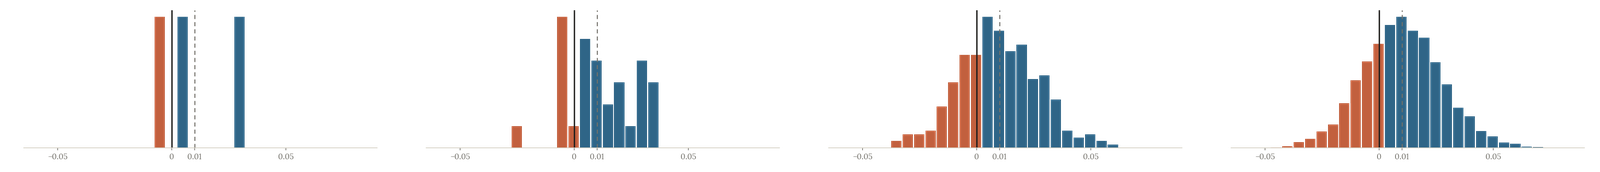

Với public 200 dòng, khoảng một phần ba số lần public xếp A ngang hoặc hơn B, dù trên toàn bộ test B hơn 0.01. Độ lệch chuẩn của chênh lệch public (0.018) lớn hơn chính chênh lệch thật. Public 1000 dòng chỉ xếp sai khoảng 5% số lần. Lý do nằm ở 140 dòng khác nhau: public 200 dòng chứa trung bình 14 dòng trong số đó.

Vì vậy hai bản chênh vài dòng trên public chưa chứng minh bản nào tốt hơn trên tập kín. Bản cuối nên được chọn bằng bằng chứng nhất quán trên validation hợp lệ; chọn bản có public cao nhất trong nhiều lượt nộp là chọn cả phần may mắn (bài 1.7).

**Hỏi nhanh.** Public có 200 dòng. Bản R07 đạt 0.815, bản R05 đạt 0.805, tức chênh nhau 2 dòng. Trên validation 5 fold, R05 hơn R07 ở cả 5 fold, trung bình hơn 0.004. Còn một lượt nộp. Nên làm gì?

- A. Chọn R07, vì public được chấm trên dữ liệu kín của đề
- B. Nộp lại R07 một lần nữa để điểm public ổn định hơn
- C. Chọn R05, vì chênh lệch public nằm trong mức nhiễu của 200 dòng
- D. Lấy trung bình R05 và R07, nộp luôn bản mới chưa kiểm

<details><summary>Đáp án</summary>

C. Chọn R05, vì chênh lệch public nằm trong mức nhiễu của 200 dòng

Chênh 0.01 trên 200 dòng là 2 dòng, nhỏ hơn độ lệch chuẩn khoảng 0.018 vừa đo, còn R05 thì thắng ở cả 5 fold. Public đúng là dữ liệu kín, nhưng quá ít dòng để tách được hai bản này. Nộp lại cùng một file cho đúng điểm cũ, vì phần public cố định, nên lặp lại không làm giảm nhiễu lấy mẫu. Trộn hai bản là tạo ra một model thứ ba chưa có bằng chứng nào.

</details>

## Giữ đường nộp luôn hoạt động

Quay lại tình huống mở bài: còn 35 phút và bài văn bản chưa có file hợp lệ. Một bản tối thiểu ngang baseline cho $N=0$, nên giá trị của nó không nằm ở điểm số lúc ấy mà ở chỗ mọi cải thiện của bài văn bản đều phải đi qua đường nộp này; không có file thì bài đó chắc chắn 0 điểm dù model tốt đến đâu. Seed thêm cho ảnh, theo bảng xếp hạng $V$ ở mục về ích lợi dự kiến, chỉ đáng khoảng 0.07 điểm dự kiến mỗi phút.

Thứ tự hợp lý là dựng và lưu bản văn bản hợp lệ trước, dùng phần còn lại để đưa nó vượt baseline, và chỉ chạy seed khi mọi việc đã có bản dự phòng.

**Hỏi nhanh.** Còn 35 phút. Phương án 1 là chạy thêm seed cho ảnh, mất 20 phút, với $p = 0.5$, tăng 2 điểm. Phương án 2 là dành 15 phút dựng một file văn bản hợp lệ, ngang baseline với $N = 0$, rồi 20 phút làm TF-IDF với $p = 0.6$, đạt $N = 20$. Điểm dự kiến tăng thêm của hai phương án là bao nhiêu?

- A. Seed được 1 điểm, văn bản được 0, vì bản đầu chỉ ngang baseline
- B. Seed được 1 điểm, văn bản được 12 điểm
- C. Seed được 2 điểm, văn bản được 20 điểm
- D. Seed được 1 điểm, văn bản được 0.34 điểm

<details><summary>Đáp án</summary>

B. Seed được 1 điểm, văn bản được 12 điểm

Seed được $0.5\cdot 2 = 1$. Với văn bản, bước đầu chắc chắn nhưng cho 0, còn bước sau cho $0.6\cdot 20 = 12$. Giá trị của bước đầu nằm ở chỗ nó mở đường cho bước sau, nên chỉ khi dừng ở bước đầu mới được 0. 2 và 20 là bỏ $p$. $0.6\cdot 20/35 \approx 0.34$ là điểm dự kiến *mỗi phút* của cả phương án, không phải tổng.

</details>

Code dưới ghi bảng dự đoán thành văn bản CSV rồi đọc lại đúng như bộ chấm sẽ đọc. ID được đọc như chuỗi để không mất số 0 ở đầu.

In [ ]:
import pandas as pd
from io import StringIO

expected_ids = ["001", "007", "010"]
submission = pd.DataFrame({
    "id": expected_ids,
    "probability": [0.15, 0.80, 0.55],
})
csv_text = submission.to_csv(index=False, lineterminator="\n")
readback = pd.read_csv(StringIO(csv_text),
                       dtype={"id": str})
assert readback.columns.tolist() == ["id", "probability"]
assert readback["id"].tolist() == expected_ids
assert readback["id"].is_unique
assert np.isfinite(readback["probability"]).all()
assert readback["probability"].between(0, 1).all()
print(csv_text.rstrip())
print("readback", readback.shape, "OK")

id,probability
001,0.15
007,0.8
010,0.55
readback (3, 2) OK


Dòng `001` còn nguyên và bảng có ba hàng, hai cột. Shape đúng chưa đủ: xác suất phải hữu hạn và nằm trong miền hợp lệ. Bài nhiều lớp còn cần kiểm thứ tự cột lớp và tổng từng hàng. Đọc lại từ văn bản CSV bắt được những lỗi mà kiểm biến trong RAM bỏ qua, như mất số 0 đầu hay thừa cột index; khi thi, ghi ra đúng tệp sẽ nộp rồi đọc lại chính tệp đó.

**Hỏi nhanh.** CSV có đúng số hàng và đúng tên cột, nhưng thứ tự ID khác với file mẫu. Đã kết luận được bài nộp đúng chưa?

- A. Đúng rồi, vì đủ số hàng và đủ tên cột là đủ yêu cầu
- B. Đúng, nếu metric trên validation local đã đủ cao
- C. Đúng, vì bộ chấm luôn tự sắp lại mọi dòng theo ID
- D. Chưa, cần biết bộ chấm ghép theo ID hay theo vị trí

<details><summary>Đáp án</summary>

D. Chưa, cần biết bộ chấm ghép theo ID hay theo vị trí

Nếu bộ chấm ghép theo ID thì thứ tự không quan trọng. Nếu ghép theo vị trí thì mọi dòng lệch đều bị chấm với nhãn của mẫu khác. Statement hoặc file mẫu quyết định điều này, không có quy ước chung nào là “luôn luôn”. Cách an toàn là sắp theo đúng thứ tự của file mẫu, và assert danh sách ID trùng khớp. Metric local cao không nói gì về cách file được ghép.

</details>

## Khi đi thi

- **Ghi yêu cầu của đề trước khi viết model.** Metric cần nhãn hay xác suất, cao hay thấp là tốt; tệp phải nộp; runtime tính từ đâu; tài nguyên nào được dùng. Đọc statement từng bài, vì nó có thể khác quy định chung.
- **Có bài nộp hợp lệ cho mọi bài trước khi tối ưu bài nào.** Bản ngang baseline cho 0 điểm chuẩn hóa nhưng mở đường cho mọi cải thiện; lưu lại từng bản đã kiểm làm dự phòng.
- **Ước lượng runtime bằng hai phép đo.** Đo hai kích thước batch trên đúng máy để tách phần cố định (khởi động, nạp model) khỏi phần theo số mẫu, rồi chừa khoảng đệm; dữ liệu lớn còn có thể hết RAM.
- **Mỗi thí nghiệm một thay đổi và một mốc dừng.** Ghi giả thuyết, split, metric, thời gian; với ba bốn việc, duyệt hết các kế hoạch thay cho chọn tham lam. Nhật ký này cũng là nguyên liệu cho báo cáo nếu đề chấm lập luận.
- **Đọc public như một phép đo có nhiễu.** Chênh vài dòng trên public nhỏ không đủ để chọn bản cuối; không dò nhãn qua scorer, không gán nhãn test bằng tay.
- **Khóa bản cuối đúng mốc.** Đóng các thay đổi chưa có bằng chứng, chạy lại từ đầu, đọc lại tệp sẽ nộp. Lỗi của hệ thống thi thì báo qua kênh chính thức với thông tin đủ tái hiện; thời gian bù và số lượt nộp do ban tổ chức quyết định.

## Tóm tắt

- Đọc kỹ yêu cầu của từng bài: metric, tệp nộp, runtime, tài nguyên được dùng.
- Có một đường nộp chạy được cho mọi bài trước khi cải thiện.
- Công thức chuẩn hóa cho biết một mức tăng metric đáng bao nhiêu điểm; thời gian, xác suất thành công và sự phụ thuộc giữa các bước quyết định làm gì trước. Với vài việc, duyệt hết các kế hoạch để tránh bẫy tham lam.
- Điểm public có nhiễu; chọn bản cuối bằng validation hợp lệ.
- Giữ thời gian cuối để chạy lại từ đầu và kiểm file nộp.

## Kiểm tra cuối bài

**Câu 1.** Phần quy định chung của một kỳ thi nêu giới hạn chạy 20 phút cho mọi bài, trừ khi statement quy định khác. Statement của bài B ghi 5 phút. Notebook của đội chạy 12 phút trên một máy giống máy chấm. Kết luận thế nào?

- A. Đạt, vì 12 phút còn dưới giới hạn chung 20 phút
- B. Đạt, vì statement chỉ là gợi ý, quy định chung mới là luật
- C. Không đạt, vì giới hạn của bài B là 5 phút theo statement
- D. Chưa biết, phải xem runtime của bài này năm trước

<details><summary>Đáp án</summary>

C. Không đạt, vì giới hạn của bài B là 5 phút theo statement

Quy định chung đã tự ghi ngoại lệ: statement nói khác thì theo statement. 12 phút vượt 5 phút, nên bài B không đạt, dù dưới 20 phút. Runtime năm trước không phải hợp đồng của năm nay. Cách sửa là giảm phần chạy trong notebook, như nạp model đã lưu nếu luật cho phép, bớt epoch, hay bớt model trong ensemble, rồi đo lại cả notebook.

</details>

**Câu 2.** Đo inference trên đúng máy chấm: 500 mẫu mất 40 giây, 2000 mẫu mất 70 giây. Test có 10 000 mẫu, giới hạn 300 giây. Giả sử thời gian gồm một phần cố định cộng một phần tỉ lệ với số mẫu. Dự báo nào hợp lý?

- A. Khoảng 230 giây, đạt, còn khoảng 70 giây đệm
- B. Khoảng 350 giây, vượt, theo tỉ lệ 70 giây mỗi 2000 mẫu
- C. Khoảng 800 giây, vượt, theo tỉ lệ 40 giây mỗi 500 mẫu
- D. Khoảng 55 giây, đạt, theo trung bình của hai lần đo

<details><summary>Đáp án</summary>

A. Khoảng 230 giây, đạt, còn khoảng 70 giây đệm

Hai điểm đo cho độ dốc $(70 - 40)/1500 = 0.02$ giây mỗi mẫu, và phần cố định $40 - 500\cdot 0.02 = 30$ giây. Vậy $30 + 10\,000\cdot 0.02 = 230$ giây. Nhân tỉ lệ từ một lần đo là coi phần cố định, như khởi động hay nạp model, lặp lại theo từng nhóm mẫu, nên ra 350 hoặc 800. Trung bình hai lần đo không phải dự báo cho 10 000 mẫu. Khoảng đệm 70 giây vẫn nên được kiểm bằng một lần chạy đủ kích thước, vì bộ nhớ có thể không tăng tuyến tính.

</details>

**Câu 3.** Bài hồi quy chấm lỗi trung bình, càng thấp càng tốt. Điểm phần thi là $100\cdot\dfrac{X_{\text{base}} - X}{X_{\text{base}} - X_{\text{best}}}$, với $X_{\text{best}} = \min(X_{\text{expert}}, X_{\text{thí sinh}})$, trong đó $X_{\text{expert}}$ là lỗi của một model mà ban giám khảo giữ kín. Lỗi lớn hơn baseline thì được 0 điểm. Biết $X_{\text{base}} = 0.50$, $X_{\text{expert}} = 0.20$, bài tốt nhất của thí sinh có lỗi 0.26, còn đội đạt $X = 0.32$. Đội được bao nhiêu điểm?

- A. 75
- B. 60
- C. 40
- D. 0

<details><summary>Đáp án</summary>

B. 60

$X_{\text{best}} = \min(0.20, 0.26) = 0.20$, nên điểm là $100\cdot(0.50 - 0.32)/(0.50 - 0.20) = 60$. 75 là lấy mốc 0.26 của thí sinh mà quên model của chuyên gia. 40 là phần khoảng cách còn lại tới mốc, $(0.32 - 0.20)/0.30$, không phải phần đã đi được. 0 là đọc nhầm chiều: với lỗi, $X < X_{\text{base}}$ nghĩa là *tốt hơn* baseline. Đứng đầu bảng thí sinh cũng chưa chắc được 100 điểm, vì mốc trên nằm ngoài tầm nhìn.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 2 · Ngày 1 · Problem 2](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-1-problems.pdf#page=14)

</details>

**Câu 4.** Có 30 phút. Cải tiến A cần 10 phút, thêm 1 điểm. Chỉ sau A mới làm được B, cần 20 phút, thêm 8 điểm. C độc lập, cần 20 phút, thêm 5 điểm. Các mức tăng đều chắc chắn, không có chi phí nào khác. Kế hoạch nào tăng điểm nhiều nhất?

- A. Chỉ làm C, được 5 điểm
- B. Làm C rồi A, được 6 điểm
- C. Chỉ làm B, được 8 điểm
- D. Làm A rồi B, được 9 điểm

<details><summary>Đáp án</summary>

D. Làm A rồi B, được 9 điểm

A rồi B dùng đúng 30 phút và tăng 9 điểm. Chọn theo điểm mỗi phút thì sẽ lấy C trước, vì 0.25 lớn hơn 0.1 của A, rồi A, được 6. “Chỉ B” không hợp lệ, vì thiếu bước tiên quyết A. “Chỉ C” bỏ phí 10 phút.

</details>

**Câu 5.** Bài đang có một bản nộp đã kiểm, đạt 30 điểm. Một thí nghiệm 25 phút sửa trực tiếp notebook ấy. Với xác suất 0.6 nó tăng 10 điểm, 0.2 không đổi, và 0.2 làm notebook hỏng mà không kịp sửa trước giờ đóng, mất cả 30 điểm. Điểm dự kiến tăng thêm khi sửa trực tiếp, và khi làm trên bản sao, giữ bản cũ để nộp nếu hỏng, lần lượt là bao nhiêu?

- A. 0 và +6
- B. +6 và +6
- C. +4 và +6
- D. 0 và 0

<details><summary>Đáp án</summary>

A. 0 và +6

Sửa trực tiếp thì kỳ vọng là $0.6\cdot 10 + 0.2\cdot 0 + 0.2\cdot(-30) = 0$. Làm trên bản sao thì nhánh hỏng quay về bản cũ, không mất gì, nên kỳ vọng là $0.6\cdot 10 = 6$. “+6 và +6” là quên nhánh hỏng. “+4” là tính nhánh hỏng như chỉ mất 10 điểm định tăng. “0 và 0” là quên rằng bản sao xóa khoản lỗ. Một lệnh sao chép vài giây biến một thí nghiệm hòa vốn thành một thí nghiệm đáng làm.

</details>

**Câu 6.** Bài dự đoán giá nhà có 5000 căn, 20 đặc trưng dạng bảng như diện tích, số phòng ngủ, vị trí, tuổi nhà, và cần giải thích được đặc trưng nào ảnh hưởng nhiều. Đã có baseline dự đoán giá trung bình để kiểm đường nộp. Nên thử model chính nào đầu tiên?

- A. MLP 5 lớp ẩn, vì mạng sâu luôn hơn model cổ điển
- B. Linear regression, vì model đơn giản nhất luôn tốt nhất
- C. Gradient boosted trees như LightGBM hoặc XGBoost
- D. kNN, vì nhà gần nhau thường có giá gần nhau

<details><summary>Đáp án</summary>

C. Gradient boosted trees như LightGBM hoặc XGBoost

Với dữ liệu bảng vài nghìn mẫu, vài chục đặc trưng, gradient boosted trees thường là một mốc mạnh. Chúng xử lý được đặc trưng khác thang đo, quan hệ phi tuyến và tương tác mà không cần chuẩn hóa, chạy nhanh trên CPU, và có feature importance để giải thích. MLP cần chuẩn hóa và phải dò nhiều tham số, với 5000 mẫu hiếm khi thắng được cây, nên “luôn hơn” là sai. Linear regression là một mốc kiểm tra tốt, nhưng bỏ sót tương tác, như giữa vị trí và diện tích. kNN phụ thuộc thang đo, và coi mọi đặc trưng nặng như nhau (bài 2.4).
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 267](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=95)

</details>

**Câu 7.** Nghi ngờ đặc trưng unigram làm mất phủ định trong câu ngắn, khiến “không tốt” bị đọc gần như “tốt”. Thí nghiệm nào kiểm giả thuyết này rõ nhất?

- A. Đổi model, tokenizer và fold cùng lúc, rồi đọc log loss tổng
- B. Chọn vài câu mà bigram đoán đúng để minh họa là nó tốt hơn
- C. Tăng kích thước model, rồi quy phần tăng điểm cho phủ định
- D. Giữ nguyên fold và classifier, thêm bigram, rồi đọc riêng nhóm câu phủ định

<details><summary>Đáp án</summary>

D. Giữ nguyên fold và classifier, thêm bigram, rồi đọc riêng nhóm câu phủ định

Chỉ có một thay đổi, cùng fold và classifier, nên chênh lệch thuộc về bigram. Đọc riêng nhóm câu ngắn có phủ định kiểm đúng cơ chế đang giả định, còn log loss tổng cho biết thay đổi có làm hỏng chỗ khác không. Đổi ba thứ cùng lúc thì không biết thứ nào có tác dụng. Chọn vài ví dụ đẹp là chọn bằng chứng theo kết luận. Tăng model rồi quy cho phủ định là gán một cơ chế chưa được kiểm. Nhóm câu phủ định cần đủ mẫu thì chênh lệch mới đọc được.

</details>

**Câu 8.** Bài phân loại chuỗi cảm biến chấm macro-F1. Luật ghi rằng nếu phát hiện thí sinh gán nhãn test bằng tay thì phần đó được 0 điểm. Model còn phân vân ở 40 chuỗi test, với xác suất từ 0.45 đến 0.55. Một bạn vẽ 40 chuỗi ấy ra và thấy có thể tự đoán nhãn. Nên làm gì?

- A. Sửa tay 40 nhãn, vì đó chỉ là một phần nhỏ của cả test
- B. Không sửa tay, mà rút quy luật từ validation rồi viết thành code
- C. Sửa tay, nhưng ghi rõ việc đó trong báo cáo cho minh bạch
- D. Nộp hai bản có và không sửa tay, giữ bản có public cao hơn

<details><summary>Đáp án</summary>

B. Không sửa tay, mà rút quy luật từ validation rồi viết thành code

Gán nhãn test bằng mắt đúng là hành vi luật cấm, bất kể bao nhiêu dòng, nên phần thi có thể về 0. Ghi vào báo cáo chỉ làm vi phạm rõ ràng hơn. Nộp bản sửa tay để đọc public vẫn là gán nhãn tay, lại còn dùng scorer làm nguồn nhãn. Việc hợp lệ là nhìn những chuỗi *validation* mà model phân vân, rút ra đặc điểm, chẳng hạn một dạng đỉnh lặp lại, rồi biến nó thành feature hoặc quy tắc bằng code, và đo trên validation.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 2 · Ngày 1 · Part 1.4](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-1-problems.pdf#page=9)

</details>

**Câu 9.** Cùng fold, đổi A thành B làm accuracy tăng 0.002 với seed 0. Ba seed khác, chọn trước khi chạy, cho chênh lệch $-0.003$, $0.000$ và $0.001$. Ta kết luận được gì?

- A. B tốt hơn, vì seed 0 là lần chạy đầu tiên được ghi lại
- B. B tốt hơn, nếu chỉ báo seed 0 và bỏ các seed nhiễu
- C. Chưa có cải thiện nhất quán, vì chênh lệch chỉ cỡ dao động giữa các seed
- D. Hai bản như nhau, vì trung bình bốn chênh lệch bằng 0

<details><summary>Đáp án</summary>

C. Chưa có cải thiện nhất quán, vì chênh lệch chỉ cỡ dao động giữa các seed

Bốn chênh lệch $0.002$, $-0.003$, $0.000$ và $0.001$ có trung bình bằng 0, trải từ $-0.003$ tới $0.002$, cùng cỡ dao động giữa các seed. “B tốt hơn” là chọn đúng lần chạy thuận lợi. “Như nhau” cũng vượt quá dữ liệu, vì bốn lần chạy không đủ để khẳng định chênh lệch bằng 0. Muốn quyết định thì thêm seed hoặc fold, hay đọc riêng nhóm lỗi mà thay đổi nhắm tới. Nếu vẫn không rõ, hãy giữ bản đơn giản hơn.

</details>

**Câu 10.** Đề chấm theo ba tiêu chí: notebook chạy trọn từ đầu đến cuối, điểm trên test kín, và chất lượng lập luận trong ô văn bản tổng kết ở cuối notebook, gồm cách tiếp cận, lý do thiết kế, và những hướng đã thử nhưng không nộp. Còn 20 phút. Notebook đã chạy trọn, nhưng ô tổng kết còn trống. Nên dùng 20 phút thế nào?

- A. Viết ô tổng kết dựa trên nhật ký, rồi chạy lại toàn bộ notebook
- B. Thử thêm một bộ tham số, vì điểm test là tiêu chí chính
- C. Xóa các cell thử nghiệm cũ cho notebook gọn hơn
- D. Bỏ ô tổng kết, vì đề ghi là không chấm phong cách code

<details><summary>Đáp án</summary>

A. Viết ô tổng kết dựa trên nhật ký, rồi chạy lại toàn bộ notebook

Ô tổng kết là một tiêu chí chấm riêng, và nhật ký thí nghiệm đã có sẵn cách tiếp cận, lý do và các hướng bị loại. Một bộ tham số mới trong 20 phút khó có bằng chứng đủ chắc, lại có thể làm hỏng tiêu chí chạy trọn. Xóa cell có thể xóa luôn biến mà cell sau cần. Đề không chấm phong cách code, nhưng có chấm chất lượng lập luận, và đó là hai thứ khác nhau. Chạy lại toàn bộ sau khi sửa để chắc tiêu chí đầu vẫn đạt.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 1 · Problem 9](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=24)

</details>

## Đọc thêm

- [IOAI 2026 — Rules & Technical Appendix](https://ioai-official.org/wp-content/uploads/2026/06/IOAI2026-Contest-Rules-and-Tehnical-Appendix.pdf), mục 2.1, 2.5–2.6 và Appendix. Đọc để phân biệt lịch thi, cách tính điểm, phản hồi và giới hạn chung của **năm 2026**.
- [IOAI 2026 — Individual Contest](https://github.com/IOAI-official/IOAI-2026/tree/main/Individual-Contest). Chọn một statement để đối chiếu runtime và dạng nộp; đó là hợp đồng riêng của từng bài.
- [USA-NA-AIO 2026 — đề Vòng 2, Ngày 1](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-1-problems.pdf), các mục Submission và Final Competition Score của từng bài. Đọc để thấy một hợp đồng đầy đủ: tệp phải nộp, GPU bắt buộc, điểm tính theo baseline và bài tốt nhất.
- James và cộng sự — [*An Introduction to Statistical Learning with Applications in Python*](https://www.statlearning.com/), chương 5. Đọc về resampling để hiểu vì sao một validation nhỏ không thể quyết định mọi thí nghiệm.
- [scikit-learn 1.7 — Cross-validation](https://scikit-learn.org/1.7/modules/cross_validation.html). Đọc cách giữ đánh giá độc lập với chọn tham số.